# CatBoost: Boosting with Categorical Features

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `telco_churn` | **Runs on:** CPU, about 3 minute(s)

Use ordered boosting and ordered target statistics to treat categories safely.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- Why target encoding can leak and how ordered statistics avoid it
- How symmetric trees work
- How to pass categorical columns natively

**Prerequisites:**

- Linear regression notebook
- Train, validation and test splits
- Confusion matrix basics

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Subscription businesses lose revenue when customers leave, and winning a new customer costs more than keeping one.

**The problem.** Predict which telecom customers will churn from contract, billing and service information.

**Why it matters.** A ranked list of at risk customers lets a retention team spend a limited budget on the right people.

**Why machine learning.** Churn depends on many interacting attributes, and the history of past customers is available.

**Why this algorithm.** Most churn columns are categorical, which is where CatBoost is designed to help.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### CatBoost: unbiased boosting with categorical features

- **Type:** foundational paper
- **Authors:** Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V. and Gulin, A.
- **Year and venue:** 2018, NeurIPS 2018; arXiv:1706.09516
- **DOI or URL:** https://arxiv.org/abs/1706.09516
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Handle categorical features and prediction shift in boosting.
- **Methodology:** Ordered boosting and ordered target statistics.
- **Dataset:** Public benchmarks listed in the paper.
- **Main findings:** Reported gains over other boosting libraries on datasets with categorical features.
- **Limitations:** Slower training than histogram libraries on some data.

### Greedy function approximation: A gradient boosting machine

- **Type:** foundational paper
- **Authors:** Friedman, J. H.
- **Year and venue:** 2001, The Annals of Statistics 29(5):1189-1232
- **DOI or URL:** https://doi.org/10.1214/aos/1013203451
- **Verification:** Crossref 2026-11-17
- **Research objective:** Cast boosting as gradient descent in function space.
- **Methodology:** Fit each new tree to the negative gradient of the loss, with shrinkage and optional subsampling.
- **Dataset:** Simulated data and a few real regression sets.
- **Main findings:** Boosted trees give accurate and robust regression and classification across loss functions.
- **Limitations:** Sequential training, sensitive to the learning rate and number of trees.

**Relationship to this notebook.** Prokhorenkova et al. introduce CatBoost. We use the library at short training length and compare native categoricals with one-hot encoding, a small check of their motivation. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Prediction shift.** Standard boosting computes gradients on the same rows it was trained on, which biases them. Ordered boosting trains with models that never saw the row they score.

**Ordered target statistic.** For a categorical value $c$ and a random permutation, row $i$ is encoded as

$$\hat x_i = \frac{\sum_{j \prec i,\; c_j = c_i} y_j + a\,p}{\sum_{j \prec i,\; c_j = c_i} 1 + a}$$

using only rows before $i$ in the permutation, with prior $p$ and weight $a$. This avoids target leakage.

**Oblivious trees.** All nodes at the same depth use the same split, which gives fast, regular predictors.

**Limitations.** Slower training than histogram libraries on large data, more memory.

## 5. Dataset Introduction

**Telco customer churn**, IBM sample data from the repository `IBM/telco-customer-churn-on-icp4d` (code licence Apache-2.0, dataset terms not stated). 7043 customers, 20 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account (`tenure` in months, `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`) and services (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`). Target `Churn` (1 = customer left). `TotalCharges` has blank strings that become missing values. The file is downloaded once and checked against a SHA-256 hash. Limit: one snapshot, no time dimension. Duplicate rows are reported in the EDA but kept, because without an identifier we cannot tell whether they are different customers.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "catboost"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("telco_churn")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: Churn | shape: (7043, 20)


,source
title,Telco customer churn
source,"IBM sample data, repository IBM/telco-customer..."
url,https://raw.githubusercontent.com/IBM/telco-cu...
license,"repository is Apache-2.0, dataset terms are no..."
doi,None
rows,7043
features,20
limits,One snapshot with no time dimension. The publi...


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (7043, 20)


,columns by dtype
str,15
int64,3
float64,2


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.000,0.000,1.00
tenure,7043.0,32.371,24.559,0.00,9.00,29.000,55.000,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.350,89.850,118.75
TotalCharges,7032.0,2283.300,2266.771,18.80,401.45,1397.475,3794.738,8684.80
Churn,7043.0,0.265,0.442,0.00,0.00,0.000,1.000,1.00


Columns with missing values: 1


,missing,percent
TotalCharges,11,0.16


Duplicate rows: 22


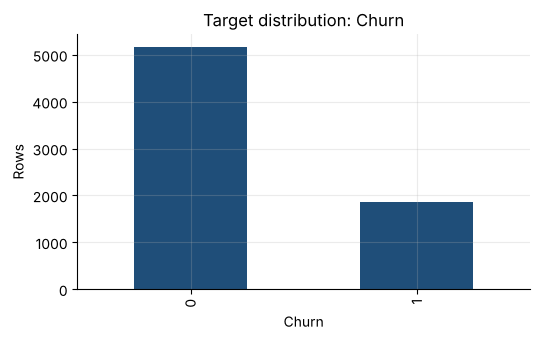

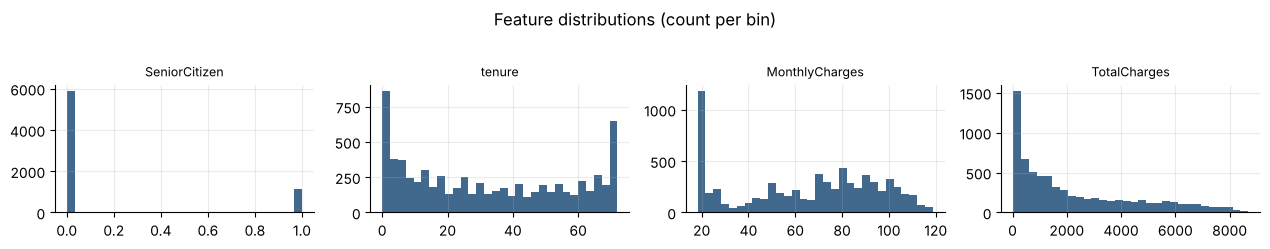

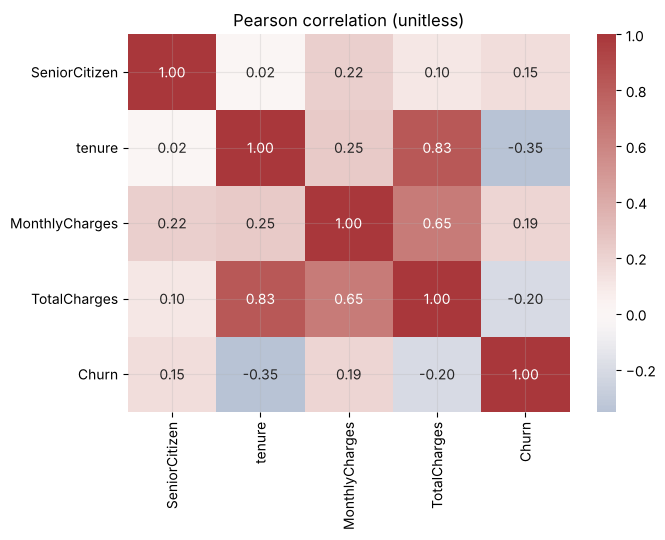

,feature,outliers,percent
0,SeniorCitizen,1142,16.21
1,tenure,0,0.00
2,MonthlyCharges,0,0.00
3,TotalCharges,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.

- `TotalCharges` is missing for new customers, so the median imputer is fitted on training rows only.
- Churn is the minority class, so we select models on PR-AUC (area under the precision recall curve) instead of accuracy.

In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=False, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 4225 1409 1409


,train,validation,test
Churn,,,
0,0.735,0.735,0.735
1,0.265,0.265,0.265


transformed train shape: (4225, 45)


## 8. Algorithm Implementation

### 8.1 Concept

CatBoost converts each category into a number using only earlier rows, so the encoding cannot memorise the row's own label.

### 8.2 Python implementation from scratch

Not implemented from scratch: ordered boosting is subtle. We implement the ordered target statistic for one column to show how it avoids leakage.

In [6]:
col = "Contract"
y_arr = y_train.values
rng = np.random.default_rng(SEED)
order = rng.permutation(len(X_train))
prior, weight = y_arr.mean(), 1.0
sums, counts, encoded = {}, {}, np.zeros(len(order))
for position, i in enumerate(order):
    value = X_train[col].iloc[i]
    encoded[i] = (sums.get(value, 0) + weight * prior) / (counts.get(value, 0) + weight)   # earlier rows only
    sums[value] = sums.get(value, 0) + y_arr[i]
    counts[value] = counts.get(value, 0) + 1
naive = X_train.groupby(col).apply(lambda g: y_arr[X_train.index.get_indexer(g.index)].mean())
naive_encoded = X_train[col].map(naive).values
print("correlation with own label, ordered encoding:", round(float(np.corrcoef(encoded, y_arr)[0, 1]), 3))
print("correlation with own label, naive mean encoding:", round(float(np.corrcoef(naive_encoded, y_arr)[0, 1]), 3))

correlation with own label, ordered encoding: 0.416
correlation with own label, naive mean encoding: 0.419


### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `iterations` | Number of trees. |
| `depth` | Depth of symmetric trees. |
| `learning_rate` | Shrinkage. |
| `cat_features` | Columns treated as categories. |
| `l2_leaf_reg` | L2 penalty. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "PR_AUC"
LOWER_IS_BETTER = False
SCORING = "average_precision"
SWEEP_PARAM = "model__depth"
SWEEP_VALUES = [3, 4, 6]

def build_pipeline():
    return make_model_pipeline(X_train, CatBoostClassifier(iterations=150, learning_rate=0.08, depth=5, random_seed=SEED, verbose=0, thread_count=2, allow_writing_files=False), scale=False, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

CatBoostClassifier(allow_writing_files=False, depth=5, iterations=150, learning_rate=0.08, random_seed=42, thread_count=2, verbose=0)


,PR_AUC,Accuracy,F1,ROC_AUC,PR_AUC
model__depth,,,,,
3,0.6497,0.8055,0.5823,0.8397,0.6497
4,0.6513,0.8062,0.5819,0.8407,0.6513
6,0.6395,0.7956,0.5596,0.8350,0.6395


best model__depth on validation: 4


refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "CatBoostClassifier": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="CatBoostClassifier", dataset="telco_churn",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654
CatBoostClassifier,0.8041,0.6655,0.5267,0.5881,0.8449,0.6619


5-fold CV average_precision: mean 0.6684, std 0.0229
saved catboost.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

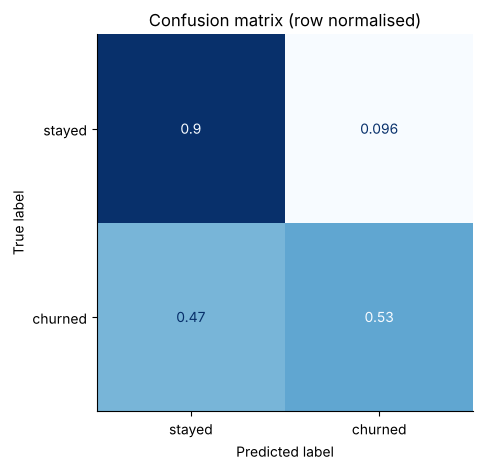

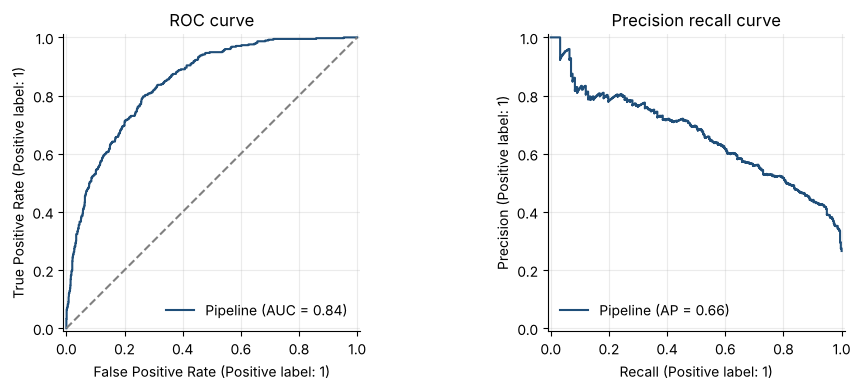

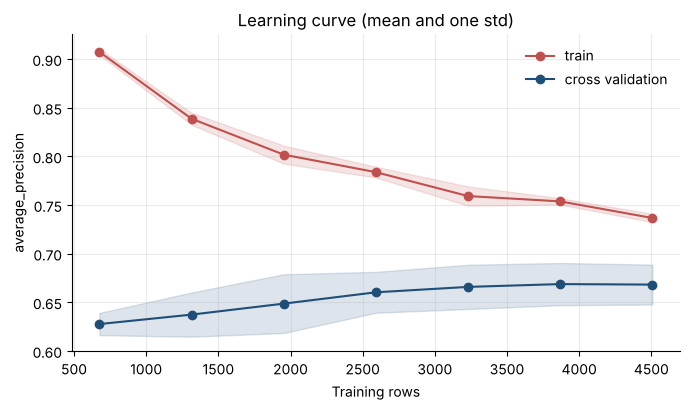

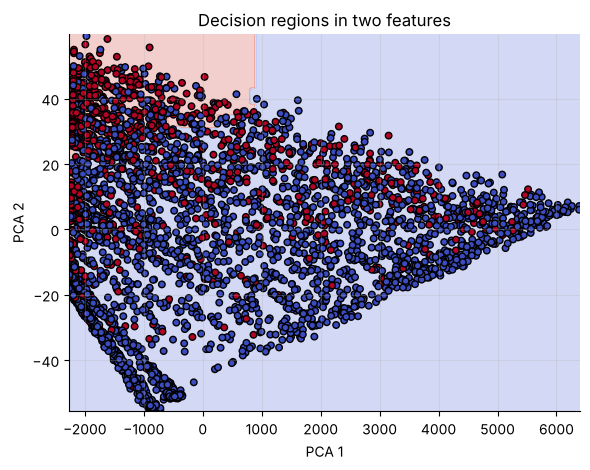

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

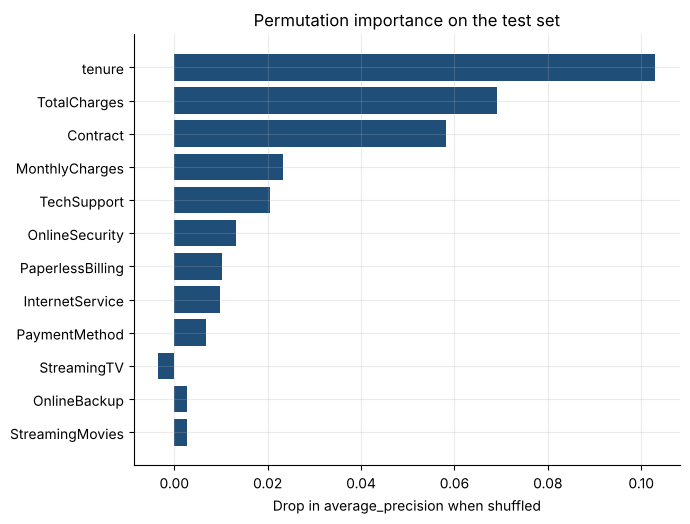

Top features: tenure, TotalCharges, Contract, MonthlyCharges, TechSupport
Misclassified test rows: 276 of 1409

Test PR_AUC: 0.6619 | baseline PR_AUC: 0.2654
Cross validation spread (std): 0.0229. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Native categoricals versus one-hot

Compare cross validated PR-AUC (3 folds to limit run time).

In [11]:
from sklearn.model_selection import cross_val_score
cat_cols = list(X_trainval.select_dtypes("object").columns)
Xn = X_trainval.copy()
Xn[cat_cols] = Xn[cat_cols].astype(str)
Xn = Xn.fillna(Xn.median(numeric_only=True))
params = dict(iterations=100, learning_rate=0.1, depth=5, random_seed=SEED, verbose=0, thread_count=2, allow_writing_files=False)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
native = []
for tr_idx, te_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xn, y_trainval):
    cb = CatBoostClassifier(cat_features=cat_cols, **params).fit(Xn.iloc[tr_idx], y_trainval.iloc[tr_idx])
    native.append(average_precision_score(y_trainval.iloc[te_idx], cb.predict_proba(Xn.iloc[te_idx])[:, 1]))
native = np.array(native)
onehot = cross_val_score(make_model_pipeline(X_trainval, CatBoostClassifier(**params), scale=False), X_trainval, y_trainval, cv=3, scoring="average_precision")
print(f"native categorical: CV PR-AUC {native.mean():.3f} +- {native.std(ddof=1):.3f}")
print(f"one-hot: CV PR-AUC {onehot.mean():.3f} +- {onehot.std(ddof=1):.3f}")

native categorical: CV PR-AUC 0.671 +- 0.010
one-hot: CV PR-AUC 0.665 +- 0.028


### Experiment 2: Best iteration on a validation set

Use the validation rows to choose the number of trees.

In [12]:
m = CatBoostClassifier(iterations=600, learning_rate=0.05, depth=5, random_seed=SEED, verbose=0, thread_count=2, allow_writing_files=False, early_stopping_rounds=40)
m.fit(Xtr, y_train, eval_set=(Xva, y_val))
print("best iteration:", m.get_best_iteration())

best iteration: 68


### Experiment 3: Learning rate and iterations

A lower learning rate needs more trees.

In [13]:
for lr, its in [(0.3, 60), (0.1, 150), (0.03, 500)]:
    m = CatBoostClassifier(iterations=its, learning_rate=lr, depth=5, random_seed=SEED, verbose=0, thread_count=2, allow_writing_files=False).fit(Xtr, y_train)
    p = m.predict_proba(Xva)[:, 1]
    from sklearn.metrics import average_precision_score
    print(f"lr={lr}, iterations={its}: validation PR-AUC {average_precision_score(y_val, p):.3f}")

lr=0.3, iterations=60: validation PR-AUC 0.641


lr=0.1, iterations=150: validation PR-AUC 0.644


lr=0.03, iterations=500: validation PR-AUC 0.647


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Prokhorenkova et al. argue that ordered statistics reduce target leakage. Our scratch cell shows the mechanism: the ordered encoding is less correlated with the row's own label than naive mean encoding. This is an illustration on one column, not a reproduction.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Tune depth, l2_leaf_reg and learning rate with early stopping, and use native categoricals in the final model.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Naive target encoding leaks.
- Ordered statistics fix that.
- CatBoost is strongest when many columns are categorical.

**Use cases.** Datasets with many categorical columns.

**Limitations.** Slower on large data.

**Recommended next notebook.** AdaBoost.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.